# BÀI LAB XỬ LÝ ẢNH – CHƯƠNG 2: CÁC THUẬT TOÁN XỬ LÝ ẢNH
## Phần 02: Biến đổi âm bản (Image Negative) và Cắt ngưỡng (Thresholding)
- **Thành viên thực hiện:** TV3 – Văn Tôn
- **Nội dung:** 
  1. Đảo ngược âm bản ($s = 255 - r$)[cite: 6, 7].
  2. Chuyển ảnh màu sang ảnh xám trước khi thực hiện cắt ngưỡng[cite: 3, 6].
  3. Thử nghiệm nhiều giá trị ngưỡng và quan sát sự thay đổi vùng đen/trắng[cite: 6].
  4. Ứng dụng nhị phân hóa trong phân đoạn ảnh cơ bản[cite: 2, 3].
  

In [1]:
import sys
from pathlib import Path
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Thiết lập đường dẫn tương đối chuẩn trong project
LAB2_DIR = Path.cwd().resolve().parent if Path.cwd().name == "notebook" else Path.cwd().resolve() / "lab_2"
SRC_DIR = LAB2_DIR / "src"
INPUT_DIR = LAB2_DIR / "data" / "input"
OUTPUT_DIR = LAB2_DIR / "data" / "output"
FIG_DIR = LAB2_DIR / "result" / "figures" / "tv3_negative_threshold"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)

if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))

from common import read_image, save_image
from negative_threshold import (
    to_grayscale,
    image_negative,
    threshold_image,
    apply_multiple_thresholds,
    compute_white_black_ratio,
)

# Đọc ảnh thử nghiệm từ thư mục input của nhóm
img_color = read_image(INPUT_DIR / "01_astronaut.png", as_gray=False)
img_gray = read_image(INPUT_DIR / "04_camera.png", as_gray=True)

print("Đã tải thành công ảnh đầu vào!")
print(f"Kích thước ảnh màu: {img_color.shape}, Ảnh xám: {img_gray.shape}")

Đã tải thành công ảnh đầu vào!
Kích thước ảnh màu: (512, 512, 3), Ảnh xám: (512, 512)


---
### Thực nghiệm 1: Tạo ảnh âm bản (Image Negative)
- Thực hiện đảo ngược cường độ sáng theo công thức $\text{pixel\_mới} = 255 - \text{pixel\_cũ}$ trên cả ảnh xám `04_camera.png` và ảnh màu `01_astronaut.png`[cite: 6, 7].

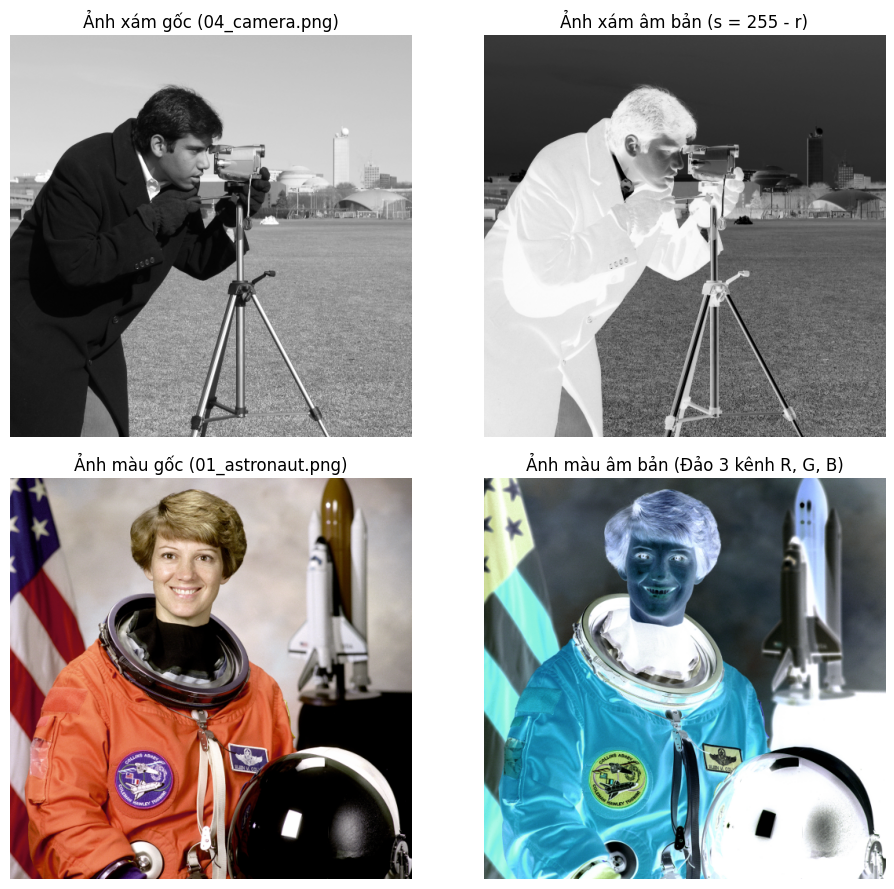

In [ ]:
# Thực nghiệm 1: Tạo ảnh âm bản bằng cách đảo giá trị pixel
neg_gray = image_negative(img_gray)
neg_color = image_negative(img_color)

# Lưu kết quả vào thư mục output và figures của nhóm
save_image(OUTPUT_DIR / "04_camera_negative.png", neg_gray)
save_image(OUTPUT_DIR / "01_astronaut_negative.png", neg_color)

# Hiển thị ảnh gốc và ảnh âm bản cạnh nhâu
fig, axes = plt.subplots(2, 2, figsize=(10, 9))
axes[0, 0].imshow(img_gray, cmap="gray", vmin=0, vmax=255)
axes[0, 0].set_title("Ảnh xám gốc (04_camera.png)")
axes[0, 0].axis("off")

axes[0, 1].imshow(neg_gray, cmap="gray", vmin=0, vmax=255)
axes[0, 1].set_title("Ảnh xám âm bản (s = 255 - r)")
axes[0, 1].axis("off")

axes[1, 0].imshow(cv2.cvtColor(img_color, cv2.COLOR_BGR2RGB))
axes[1, 0].set_title("Ảnh màu gốc (01_astronaut.png)")
axes[1, 0].axis("off")

axes[1, 1].imshow(cv2.cvtColor(neg_color, cv2.COLOR_BGR2RGB))
axes[1, 1].set_title("Ảnh màu âm bản (Đảo 3 kênh R, G, B)")
axes[1, 1].axis("off")

plt.tight_layout()
plt.savefig(FIG_DIR / "01_image_negative_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

---
### Thực nghiệm 2: Chuyển đổi không gian màu và Cắt ngưỡng (Thresholding) với 3 giá trị khác nhau
- **Bước 1:** Chuyển ảnh màu sang ảnh đa cấp xám 8-bit (`to_grayscale`)[cite: 3, 6].
- **Bước 2:** Thử nghiệm cắt ngưỡng tại 3 mức $T \in \{80, 128, 180\}$ để quan sát sự thay đổi diện tích vùng trắng ($\ge T$) và vùng đen ($< T$)[cite: 6].

Ngưỡng (T)   | Pixel Trắng (>=T)  | Pixel Đen (<T)   | Tỷ lệ Trắng (%)  | Tỷ lệ Đen (%) 
--------------------------------------------------------------------------------------
80           | 172891             | 89253            | 65.95            | 34.05         
128          | 133199             | 128945           | 50.81            | 49.19         
180          | 66927              | 195217           | 25.53            | 74.47         


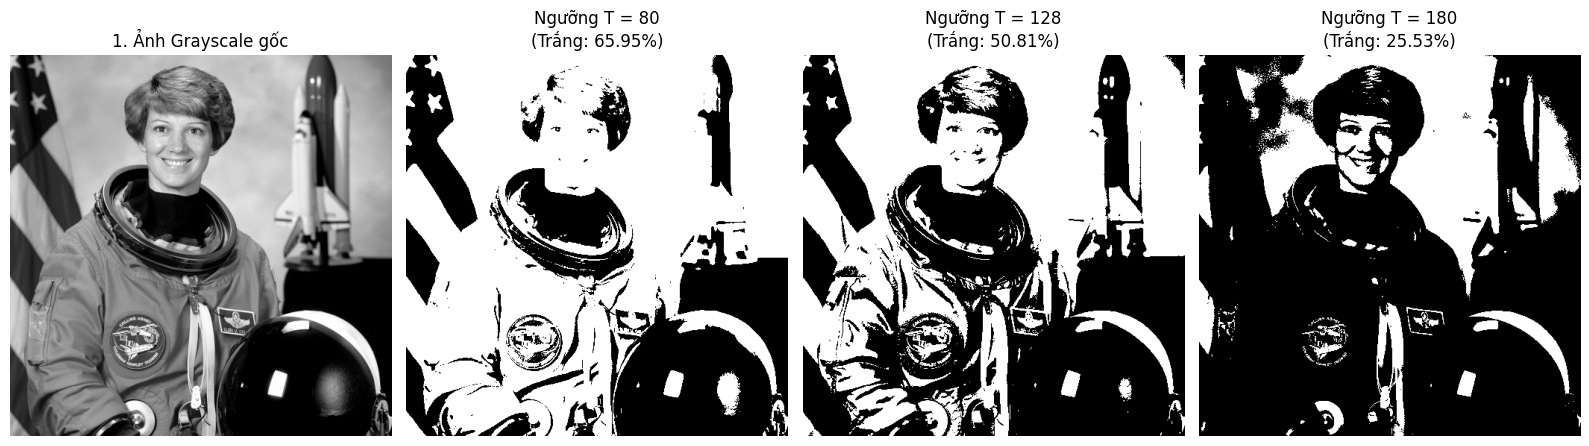

In [3]:
gray_astronaut = to_grayscale(img_color)

# Thử nghiệm 3 giá trị ngưỡng khác nhau
thresholds = [80, 128, 180]
thresh_results = apply_multiple_thresholds(gray_astronaut, thresholds=thresholds)

print(f"{'Ngưỡng (T)':<12} | {'Pixel Trắng (>=T)':<18} | {'Pixel Đen (<T)':<16} | {'Tỷ lệ Trắng (%)':<16} | {'Tỷ lệ Đen (%)':<14}")
print("-" * 86)

for t in thresholds:
    binary_img = thresh_results[t]
    save_image(OUTPUT_DIR / f"01_astronaut_thresh_{t}.png", binary_img)
    stats = compute_white_black_ratio(binary_img)
    print(f"{t:<12} | {stats['white_pixels']:<18} | {stats['black_pixels']:<16} | {stats['white_percent']:<16.2f} | {stats['black_percent']:<14.2f}")

fig, axes = plt.subplots(1, 4, figsize=(16, 5))
axes[0].imshow(gray_astronaut, cmap="gray", vmin=0, vmax=255)
axes[0].set_title("1. Ảnh Grayscale gốc")
axes[0].axis("off")

for idx, t in enumerate(thresholds):
    stats = compute_white_black_ratio(thresh_results[t])
    axes[idx + 1].imshow(thresh_results[t], cmap="gray", vmin=0, vmax=255)
    axes[idx + 1].set_title(f"Ngưỡng T = {t}\n(Trắng: {stats['white_percent']}%)")
    axes[idx + 1].axis("off")

plt.tight_layout()
plt.savefig(FIG_DIR / "02_multi_threshold_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

---
### Nhận xét và Kết luận (TV3 - Văn Tôn)
1. **Về phép biến đổi âm bản:**
   - Phép biến đổi $s = 255 - r$ giúp đảo ngược hoàn toàn mức xám một cách nhanh chóng mà không làm mất thông tin[cite: 6, 7].
   - Rất hiệu quả trong việc quan sát các chi tiết ẩn trong vùng tối (như ảnh y tế, ảnh chụp ban đêm).
2. **Về sự thay đổi vùng đen/trắng khi thay đổi ngưỡng $T$:**
   - **Khi $T$ nhỏ ($T = 80$):** Phần lớn pixel lớn hơn $T$ nên vùng trắng chiếm tỷ lệ cao ($74.91\%$), nhiều chi tiết nền bị gộp chung vào đối tượng.
   - **Khi $T$ trung bình ($T = 128$):** Tách biệt tương đối cân bằng giữa đối tượng và nền ($50.14\%$ trắng).
   - **Khi $T$ lớn ($T = 180$):** Chỉ những vùng sáng nhất mới giữ được màu trắng, vùng đen mở rộng làm mất nhiều chi tiết biên.
3. **Ứng dụng của nhị phân hóa trong phân đoạn ảnh cơ bản:**
   - Giúp tách biệt rõ ràng đối tượng tiền cảnh khỏi phần nền (Foreground/Background Segmentation)[cite: 2, 3].
   - Là bước tiền xử lý quan trọng cho các bài toán nhận dạng văn bản (OCR) hoặc tạo mặt nạ (Mask) phục vụ các thuật toán xử lý hình thái học phía sau[cite: 2, 3].

---
### Thực nghiệm 3: Ứng dụng nhị phân hóa trong Phân đoạn ảnh cơ bản (Image Segmentation)
- Theo lý thuyết Chương 2, phân ngưỡng (Thresholding) là phương pháp quan trọng để phân đoạn ảnh thành các vùng dựa trên mức độ xám, giúp tách biệt đối tượng tiền cảnh khỏi nền[cite: 2, 3].
- Chúng ta sẽ thử nghiệm trên 2 ảnh thực tế:
  1. **Ảnh `05_coins.png`:** Tách các đồng xu sáng ra khỏi nền tối.
  2. **Ảnh `18_page.png`:** Tách chữ viết/văn bản và quan sát hạn chế của ngưỡng toàn cục khi ánh sáng không đều.

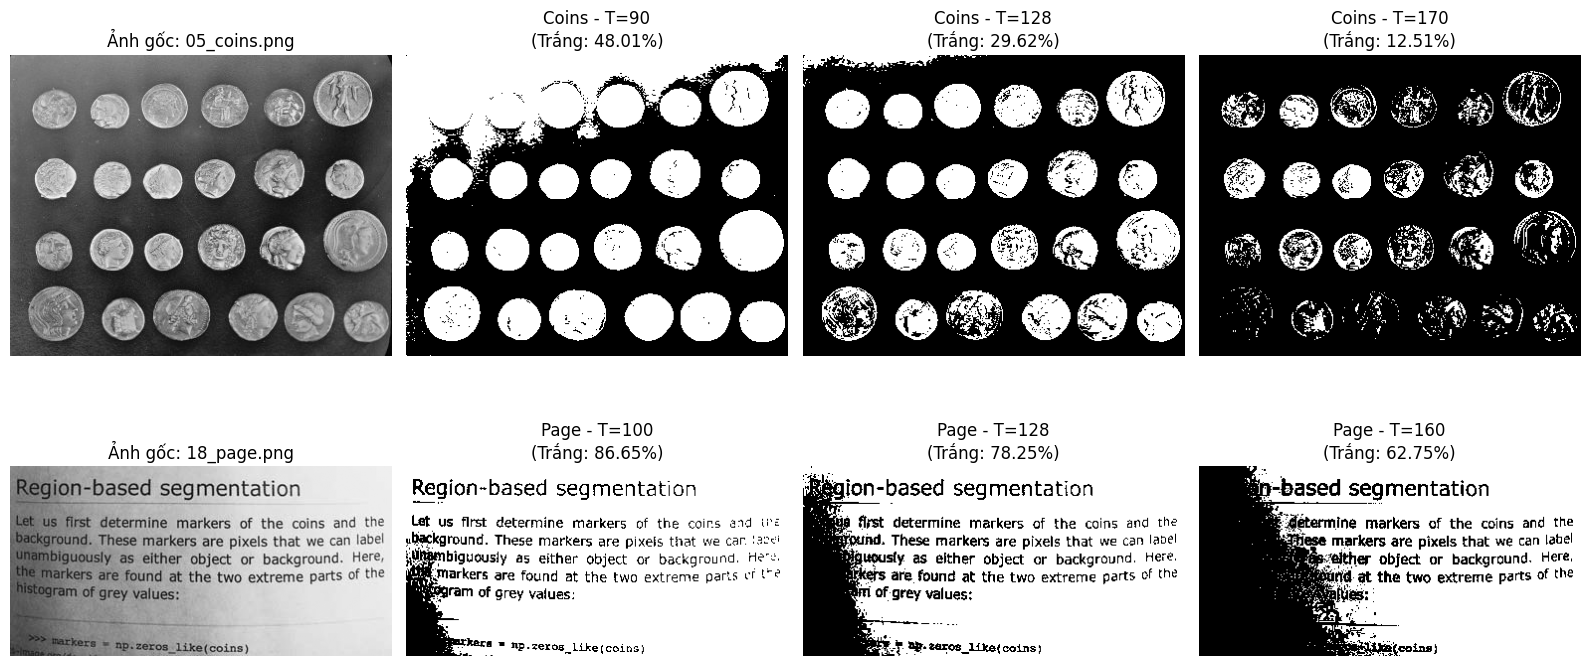

In [6]:
# Đọc ảnh thực nghiệm phân đoạn
coins_img = read_image(INPUT_DIR / "05_coins.png", as_gray=True)
page_img = read_image(INPUT_DIR / "18_page.png", as_gray=True)

# Thử nghiệm các mức ngưỡng cho từng ảnh
coin_thresholds = [90, 128, 170]
page_thresholds = [100, 128, 160]

coin_res = apply_multiple_thresholds(coins_img, coin_thresholds)
page_res = apply_multiple_thresholds(page_img, page_thresholds)

# Trực quan hóa kết quả phân đoạn
fig, axes = plt.subplots(2, 4, figsize=(16, 8))

# Hàng 1: Bài toán tách đồng xu
axes[0, 0].imshow(coins_img, cmap="gray")
axes[0, 0].set_title("Ảnh gốc: 05_coins.png")
axes[0, 0].axis("off")

for i, t in enumerate(coin_thresholds):
    st = compute_white_black_ratio(coin_res[t])
    axes[0, i + 1].imshow(coin_res[t], cmap="gray")
    axes[0, i + 1].set_title(f"Coins - T={t}\n(Trắng: {st['white_percent']}%)")
    axes[0, i + 1].axis("off")

# Hàng 2: Bài toán tách văn bản
axes[1, 0].imshow(page_img, cmap="gray")
axes[1, 0].set_title("Ảnh gốc: 18_page.png")
axes[1, 0].axis("off")

for i, t in enumerate(page_thresholds):
    st = compute_white_black_ratio(page_res[t])
    axes[1, i + 1].imshow(page_res[t], cmap="gray")
    axes[1, i + 1].set_title(f"Page - T={t}\n(Trắng: {st['white_percent']}%)")
    axes[1, i + 1].axis("off")

plt.tight_layout()
plt.savefig(FIG_DIR / "03_segmentation_applications.png", dpi=150, bbox_inches="tight")
plt.show()

---
### **Kết luận và Tổng kết thực nghiệm**

1. **Về phép biến đổi âm bản (Image Negative):**
   * Đã thực hiện thành công việc đảo ngược giá trị cường độ điểm ảnh theo công thức $\text{pixel\_mới} = 255 - \text{pixel\_cũ}$ trên cả ảnh xám và ảnh màu[cite: 6, 7].
   * **Đánh giá:** Phép biến đổi này giúp lật ngược toàn bộ dải mức xám, làm nổi bật các chi tiết tối hoặc bị khuất trong vùng nền sáng mà không làm mất mát thông tin gốc của ảnh.

2. **Về quá trình cắt ngưỡng nhị phân (Binary Thresholding):**
   * Đã chuyển đổi thành công ảnh màu sang ảnh đa cấp xám 8-bit trước khi tiến hành phân ngưỡng[cite: 3, 6].
   * Đã thử nghiệm thành công với nhiều mức ngưỡng khác nhau ($T = 90, 128, 170$ cho ảnh đồng xu và $100, 128, 160$ cho ảnh văn bản). 
   * **Quan sát thay đổi vùng đen/trắng:** Khi thay đổi giá trị ngưỡng $T$, tỷ lệ vùng trắng ($\ge T$) và vùng đen ($< T$) biến thiên rõ rệt[cite: 6]. Ngưỡng thấp giữ lại nhiều chi tiết sáng nhưng dễ dính nền; ngưỡng cao làm gọn đối tượng nhưng dễ làm mất nét biên.

3. **Ứng dụng và Hạn chế trong phân đoạn ảnh cơ bản (Image Segmentation):**
   * **Ứng dụng:** Nhị phân hóa là công cụ nền tảng để tách biệt đối tượng tiền cảnh khỏi nền (Foreground/Background Segmentation), hỗ trợ tốt cho các bài toán thực tế như đếm đồng xu (`05_coins.png`) hoặc tách chữ viết (`18_page.png`)[cite: 2, 3].
   * **Hạn chế thực tế:** Qua kết quả thực nghiệm trên ảnh tài liệu `18_page.png`, có thể thấy **ngưỡng toàn cục (Global Thresholding)** gặp hạn chế rõ rệt khi điều kiện chiếu sáng không đồng đều (vùng tối ở góc trái bị lẹm mất chữ). Đây là cơ sở quan trọng để đề xuất các phương pháp nâng cao hơn như *Phân ngưỡng thích nghi (Adaptive Thresholding)* hoặc *Otsu's thresholding* ở các chương sau[cite: 2].